# Étape ACP — Identifier les variables clés du rendement

**Demande de la mission :** réaliser une analyse en composantes principales (ACP) sur le jeu *Agriculture Crop Yield* pour identifier les variables clés, puis valider l'analyse avec le jeu *Crop Yield Prediction* (FAO).

**L'ACP en deux phrases.** Elle résume un grand nombre de variables en quelques « axes », chacun étant une combinaison des variables d'origine. Les variables portées par le même axe varient ensemble : si le rendement et la pluie sont sur le même axe, ils montent et descendent ensemble.

| Étape | Données | Objectif |
|---|---|---|
| 1 | Agriculture Crop Yield (DS1), 1 million de parcelles | Repérer les variables qui vont avec le rendement, et celles qui n'y sont pas liées dans ces données |
| 2 | Crop Yield Prediction (FAO), données réelles | Vérifier ces résultats sur des rendements réels |
| 3 | Synthèse | Comparer avec l'importance des variables dans le modèle final (étape 2) |

**Ce que l'ACP peut et ne peut pas dire.**
- L'ACP est une méthode **descriptive** : elle montre quelles variables varient ensemble. Le rendement est placé parmi les variables analysées, ce qui permet de voir lesquelles varient avec lui.
- Elle ne mesure pas, à elle seule, le **pouvoir prédictif** d'une variable. Chaque conclusion est donc recoupée par deux mesures supervisées : le lien direct avec le rendement (partie 3) et la précision du modèle avec ou sans la variable (étape 2).
- Elle ne voit que ce que contiennent les données : une variable sans lien **dans ces données** peut compter dans la réalité.

Le code des calculs et des graphiques est dans `src/acp.py`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Le notebook est dans notebooks/ : on ajoute la racine du projet pour importer src/
sys.path.insert(0, str(Path.cwd().parent))
from src import acp

acp.appliquer_style()
acp.SORTIE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)   # 3 décimales, pas de notation scientifique

## 1. ACP sur Agriculture Crop Yield (DS1)

**Variables actives** (elles construisent les axes) : pluie, température, durée de culture, engrais (oui/non), irrigation (oui/non) et rendement.

**Variables supplémentaires** (projetées après coup, sans influencer les axes) : culture, région, type de sol, météo dominante.

Les variables sont **centrées-réduites** : chacune est ramenée à la même échelle, sinon la pluie (en centaines de mm) écraserait l'engrais (0 ou 1).

In [2]:
ds1 = acp.preparer_ds1()
res1 = acp.faire_acp(ds1, acp.VARIABLES_DS1, acp.QUALITATIVES_DS1)
print(f"{res1.n_individus:,} parcelles analysées (rendements négatifs retirés)")
pd.DataFrame({"Valeur propre": res1.valeurs_propres, "Information (%)": res1.inertie_pct,
              "Cumul (%)": res1.inertie_pct.cumsum()})

999,769 parcelles analysées (rendements négatifs retirés)


,Valeur propre,Information (%),Cumul (%)
F1,1.954,32.574,32.574
F2,1.003,16.718,49.292
F3,1.001,16.682,65.973
F4,1.000,16.667,82.640
F5,0.997,16.618,99.259
F6,0.044,0.741,100.000


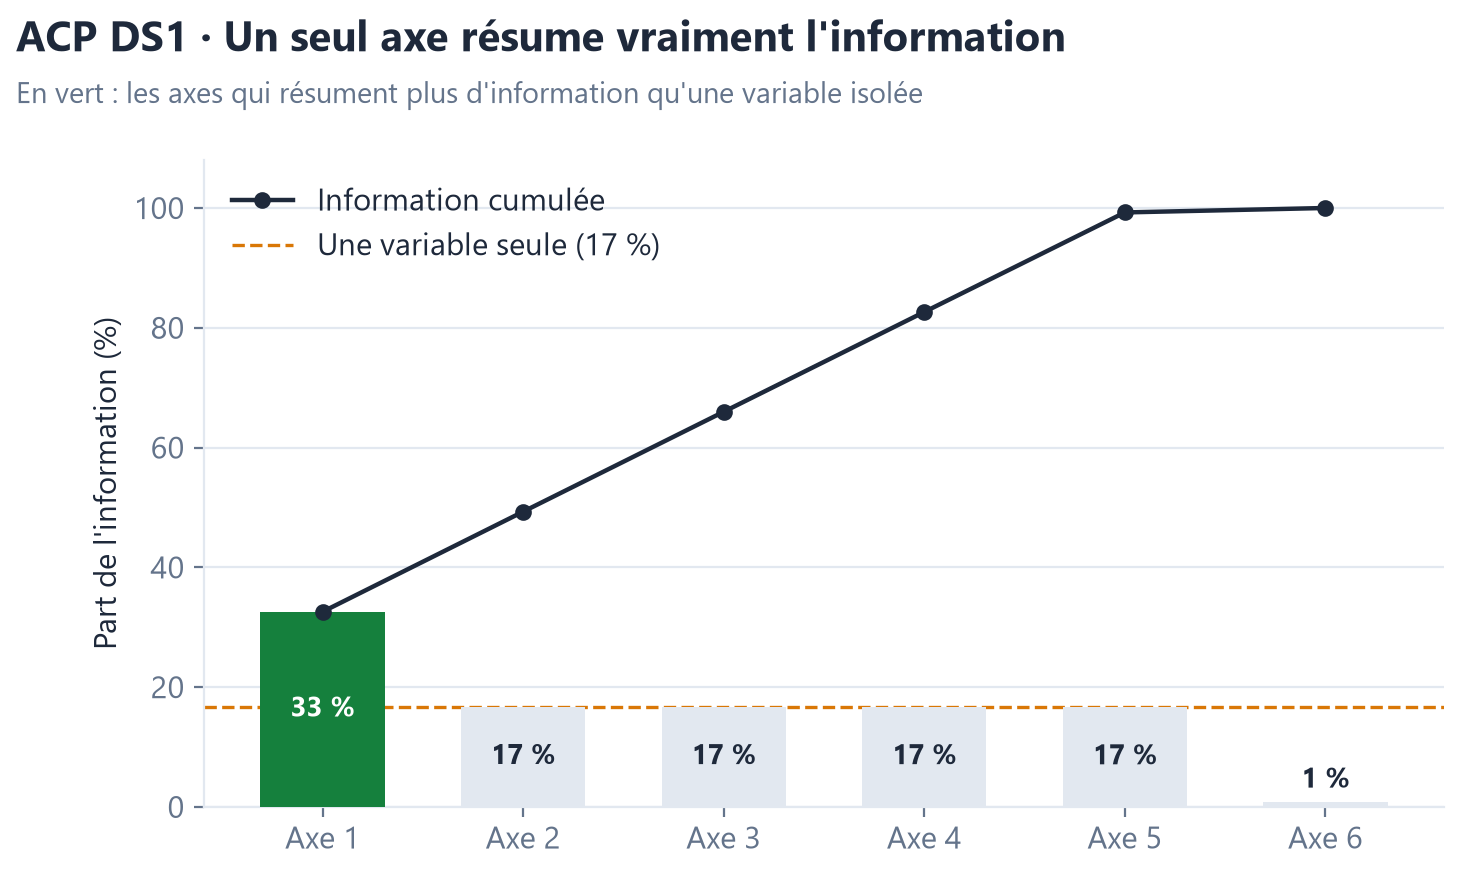

In [3]:
acp.fig_eboulis(res1, "ACP DS1 · Un seul axe résume vraiment l'information", acp.SORTIE / "01_ds1_eboulis.png")
display(Image(acp.SORTIE / "01_ds1_eboulis.png", width=760))

**Lecture.**
- **Seul l'axe 1 dépasse nettement le seuil** d'une variable isolée (33 % contre 17 %). Les axes 2 à 5 valent chacun exactement ce seuil : ils ne regroupent rien.
- **Ce profil est typique de variables indépendantes entre elles** : dans DS1, la pluie, la température, l'engrais, l'irrigation et la durée de culture ont été tirées au hasard, séparément. Il n'y a donc pas de variables redondantes à fusionner.
- **Le dernier axe ne contient presque rien** (moins de 1 %). Le rendement est donc presque entièrement déterminé par les autres variables : c'est une combinaison simple de la pluie, de l'engrais, de l'irrigation et de la température.

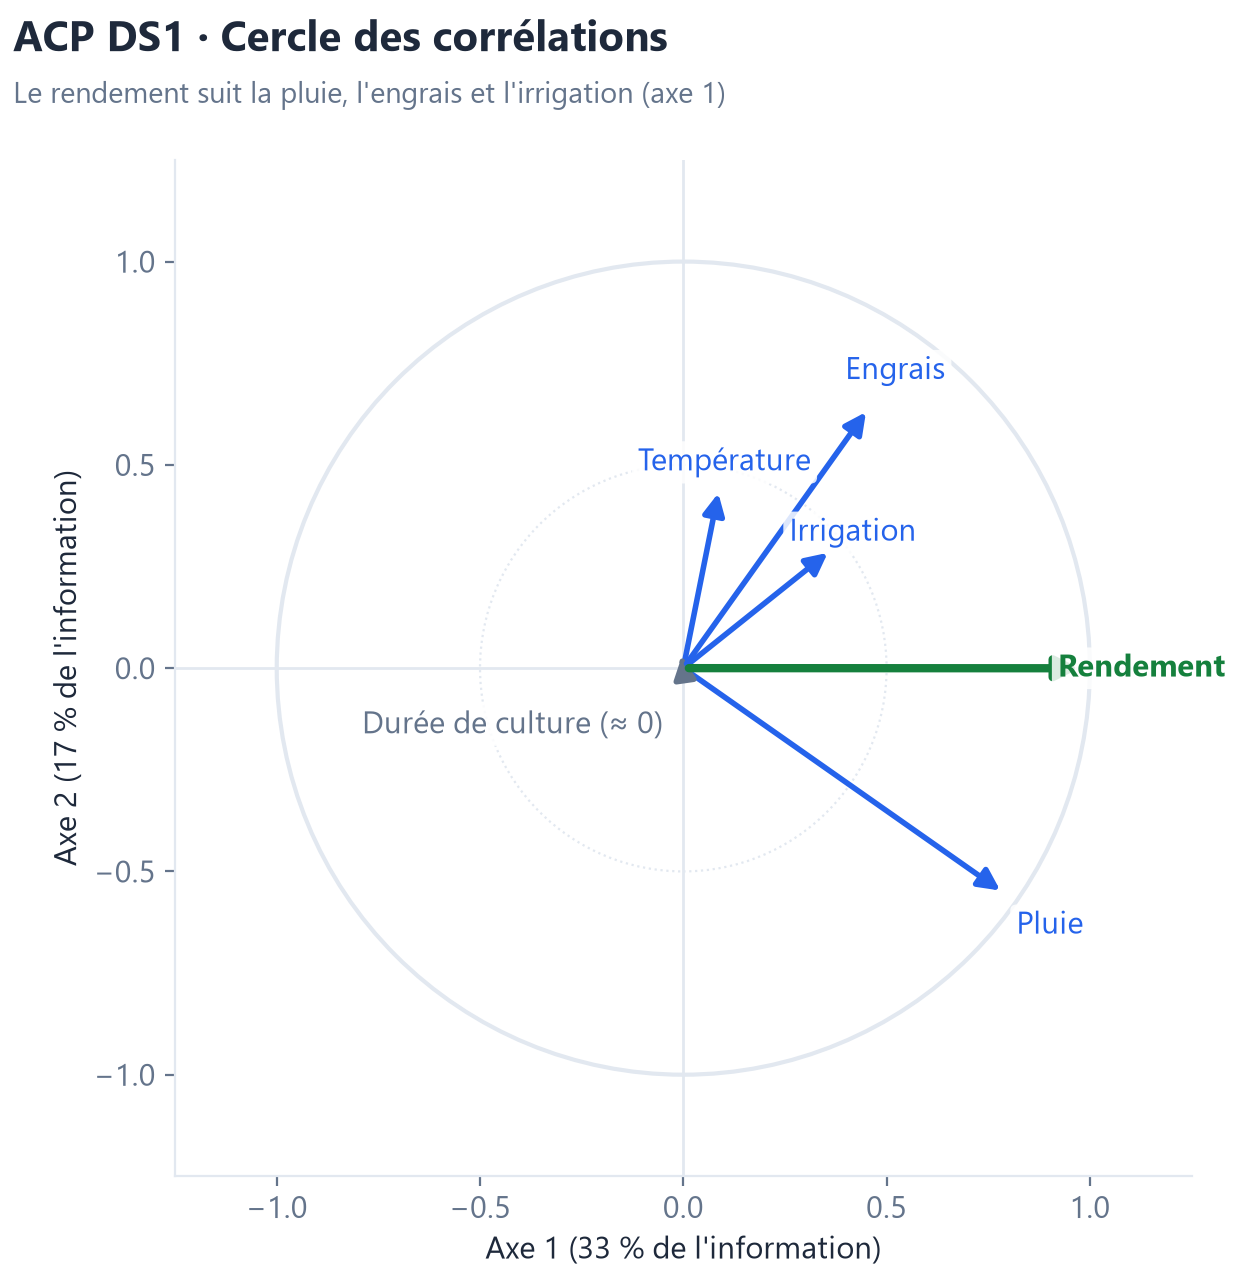

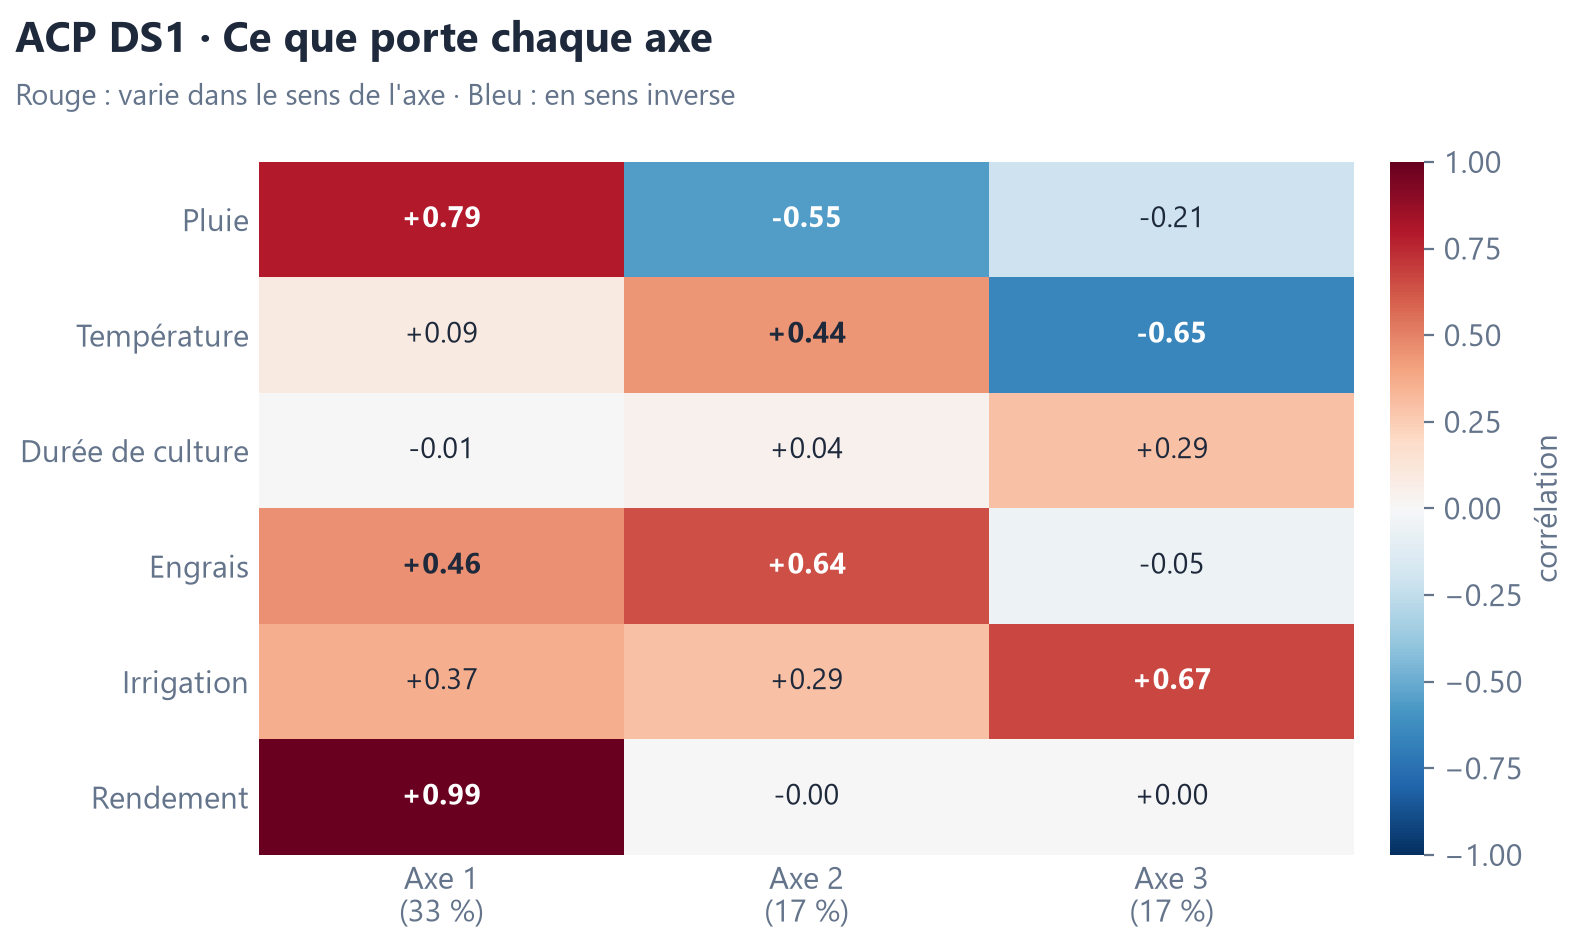

,F1,F2,F3
Pluie,0.791,-0.555,-0.206
Température,0.089,0.444,-0.650
Durée de culture,-0.006,0.042,0.293
Engrais,0.457,0.641,-0.052
Irrigation,0.366,0.292,0.669
Rendement,0.989,-0.000,0.001


In [4]:
acp.fig_cercle(res1, "ACP DS1 · Cercle des corrélations", acp.SORTIE / "02_ds1_cercle.png",
               "Le rendement suit la pluie, l'engrais et l'irrigation (axe 1)")
acp.fig_correlations_axes(res1, "ACP DS1 · Ce que porte chaque axe", acp.SORTIE / "03_ds1_correlations_axes.png")
display(Image(acp.SORTIE / "02_ds1_cercle.png", width=560))
display(Image(acp.SORTIE / "03_ds1_correlations_axes.png", width=640))
res1.correlations.iloc[:, :3].rename(index=acp.LIBELLES)

**Lecture : l'axe 1 est l'axe du rendement.**

| Variable | Corrélation avec l'axe 1 | Rôle |
|---|---|---|
| Rendement | +0,99 | L'axe 1 *est* le rendement |
| Pluie | +0,79 | **Variable clé n° 1** |
| Engrais | +0,46 | **Variable clé n° 2** |
| Irrigation | +0,37 | **Variable clé n° 3** |
| Température | +0,09 | Effet faible |
| Durée de culture | −0,01 | **Aucun effet** |

Les axes 2 et 3 ne font qu'opposer entre elles des variables sans lien avec le rendement (corrélation du rendement : 0,00) : ils n'apportent rien pour le prédire.

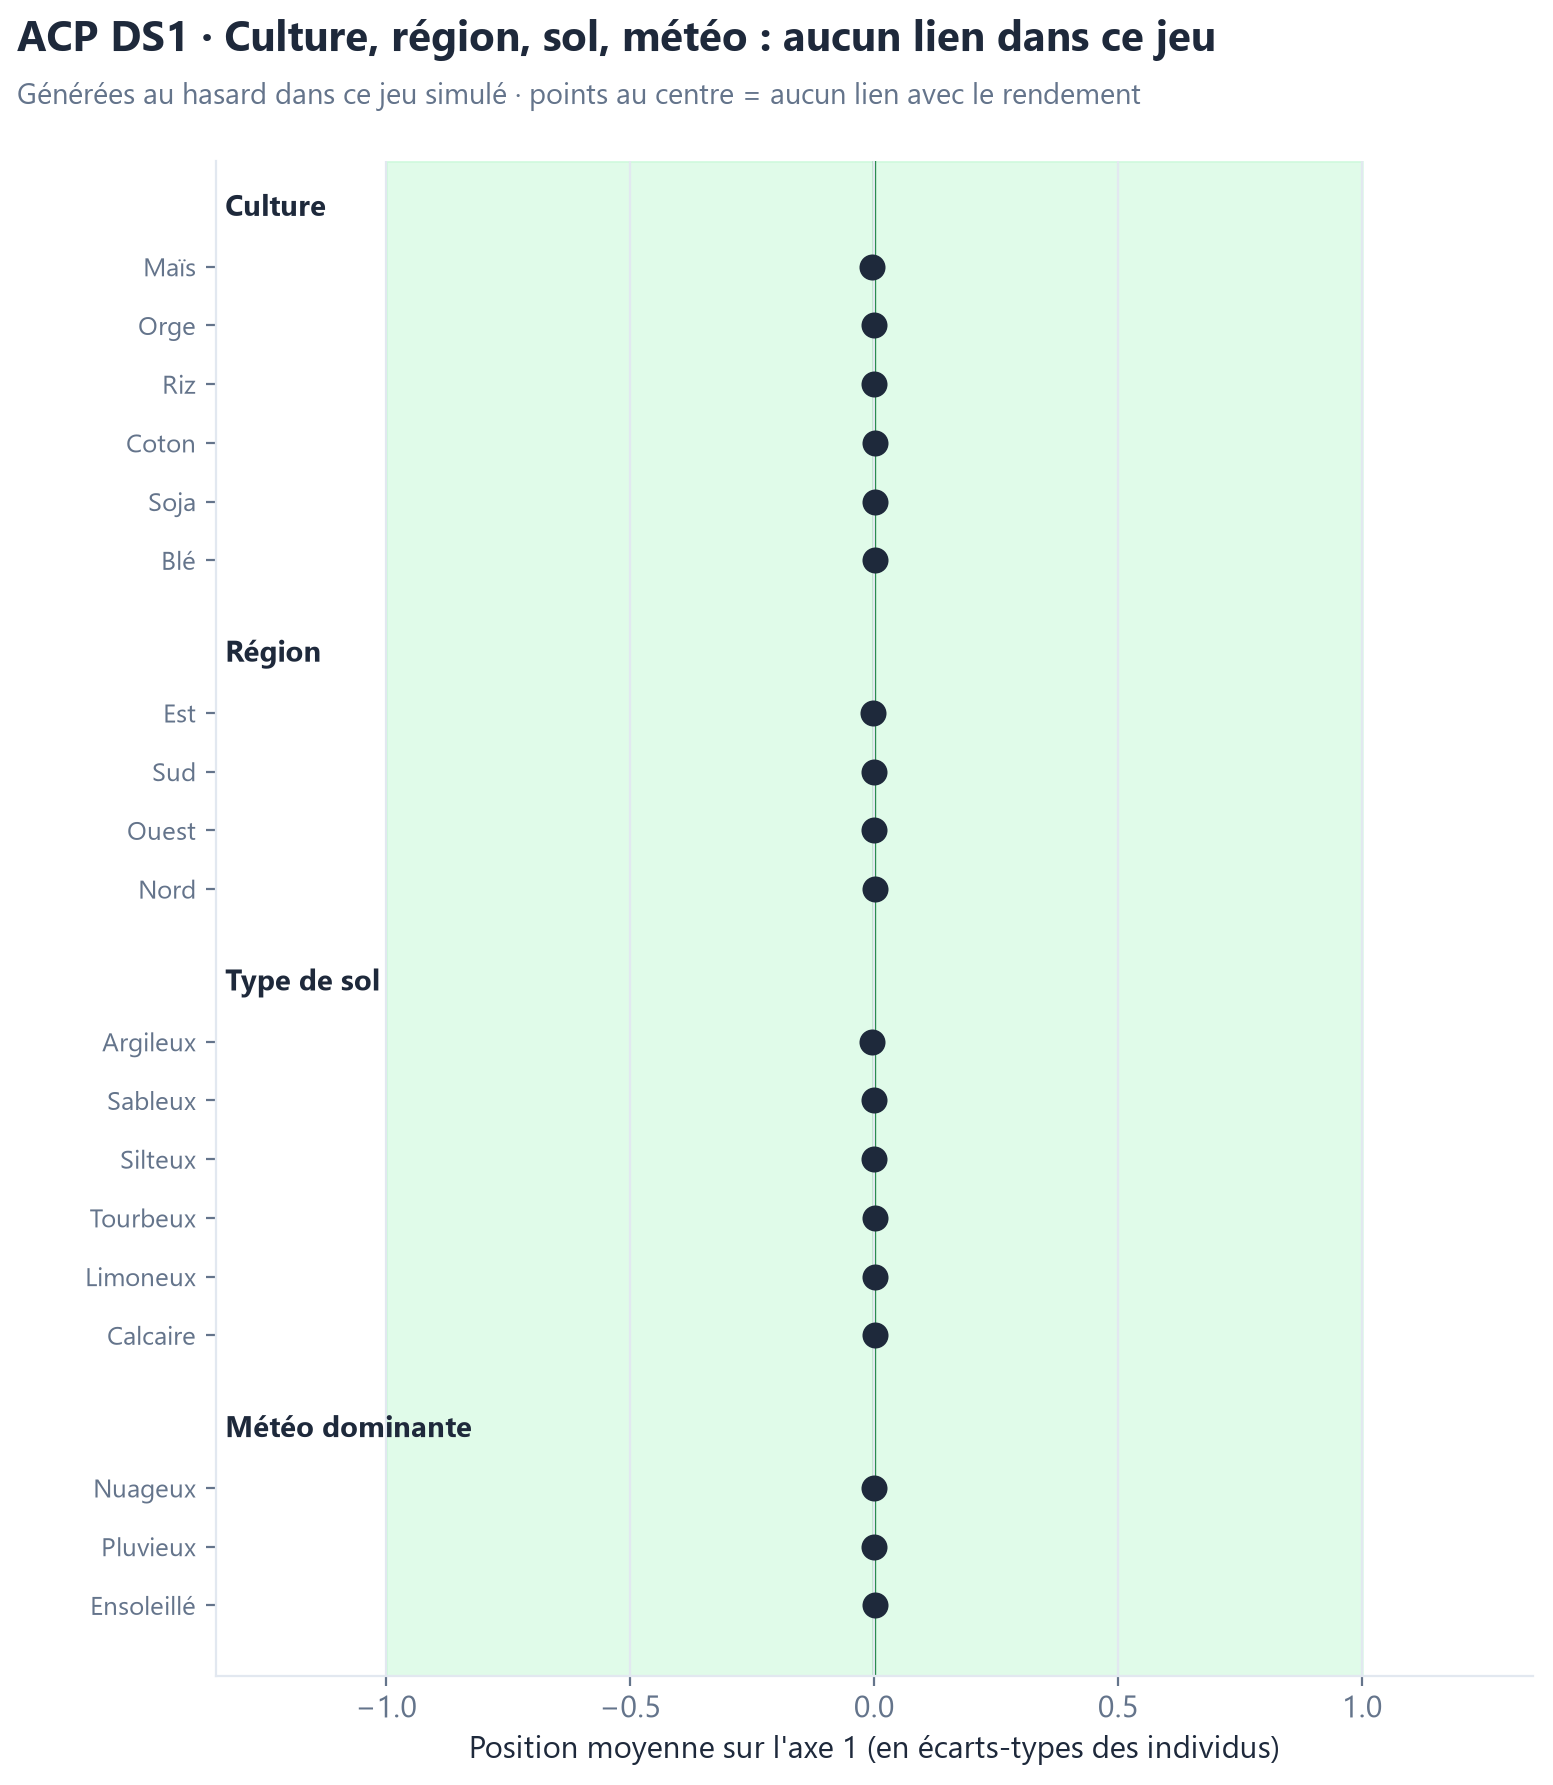

,Part de l'axe 1 expliquée (%)
Culture,0.001
Région,0.000
Type de sol,0.000
Météo dominante,0.000


In [5]:
acp.fig_qualitatives(res1, "ACP DS1 · Culture, région, sol, météo : aucun lien dans ce jeu",
                     acp.SORTIE / "04_ds1_qualitatives.png",
                     "Générées au hasard dans ce jeu simulé · points au centre = aucun lien avec le rendement")
display(Image(acp.SORTIE / "04_ds1_qualitatives.png", width=680))
(res1.eta2_pct[["F1"]].rename(columns={"F1": "Part de l'axe 1 expliquée (%)"})
 .rename(index=acp.LIBELLES).round(4))

**Lecture.** Toutes les modalités se placent au centre de l'axe du rendement : chacune de ces variables explique moins de 0,001 % de l'axe 1.
- **Région, type de sol, météo dominante** : aucun lien avec le rendement dans ce jeu, où elles ont été générées au hasard.
- **Culture : aucun lien non plus dans DS1.** Le rendement y est le même (4,65 t/ha en moyenne) quelle que soit la culture. Or le but de l'application est justement de choisir une culture : DS1 seul ne le permet pas. C'est ce qui a motivé la fusion avec les données FAO à l'étape 1.
- **Ces variables ne sont pas redondantes :** si la région ou la météo reprenaient l'information de la température ou de la pluie, elles se placeraient avec elles. Elles sont simplement indépendantes de tout le reste.

**Attention : c'est une propriété du jeu simulé, pas de l'agriculture réelle.** En pratique, le sol compte (réserve en eau, pH, nutriments) ; ces données ne permettent simplement pas de mesurer son effet.

**Conclusion de l'ACP sur DS1 :** dans ce jeu, les variables liées au rendement sont **la pluie, l'engrais et l'irrigation**, puis la température. Durée de culture, région, sol et météo dominante n'y ont aucun lien mesurable avec le rendement.

## 2. Validation sur les données réelles (FAO)

**Données :** 6 582 observations réelles (pays, culture, année) pour les quatre cultures communes, nettoyées à l'étape 1.

**Variables actives :** pluie, température, pesticides et rendement. Les pesticides sont pris en logarithme, car quelques grands pays en utilisent des centaines de milliers de tonnes. La FAO n'indique ni engrais ni irrigation : les **pesticides servent d'indicateur d'intensification** de l'agriculture du pays.

**Variable supplémentaire :** la culture.

In [6]:
fao = acp.preparer_fao()
res2 = acp.faire_acp(fao, acp.VARIABLES_FAO, ("Crop",))
print(f"{res2.n_individus:,} observations FAO")
pd.DataFrame({"Valeur propre": res2.valeurs_propres, "Information (%)": res2.inertie_pct,
              "Cumul (%)": res2.inertie_pct.cumsum()})

6,582 observations FAO


,Valeur propre,Information (%),Cumul (%)
F1,1.698,42.445,42.445
F2,1.138,28.447,70.892
F3,0.674,16.846,87.739
F4,0.491,12.261,100.000


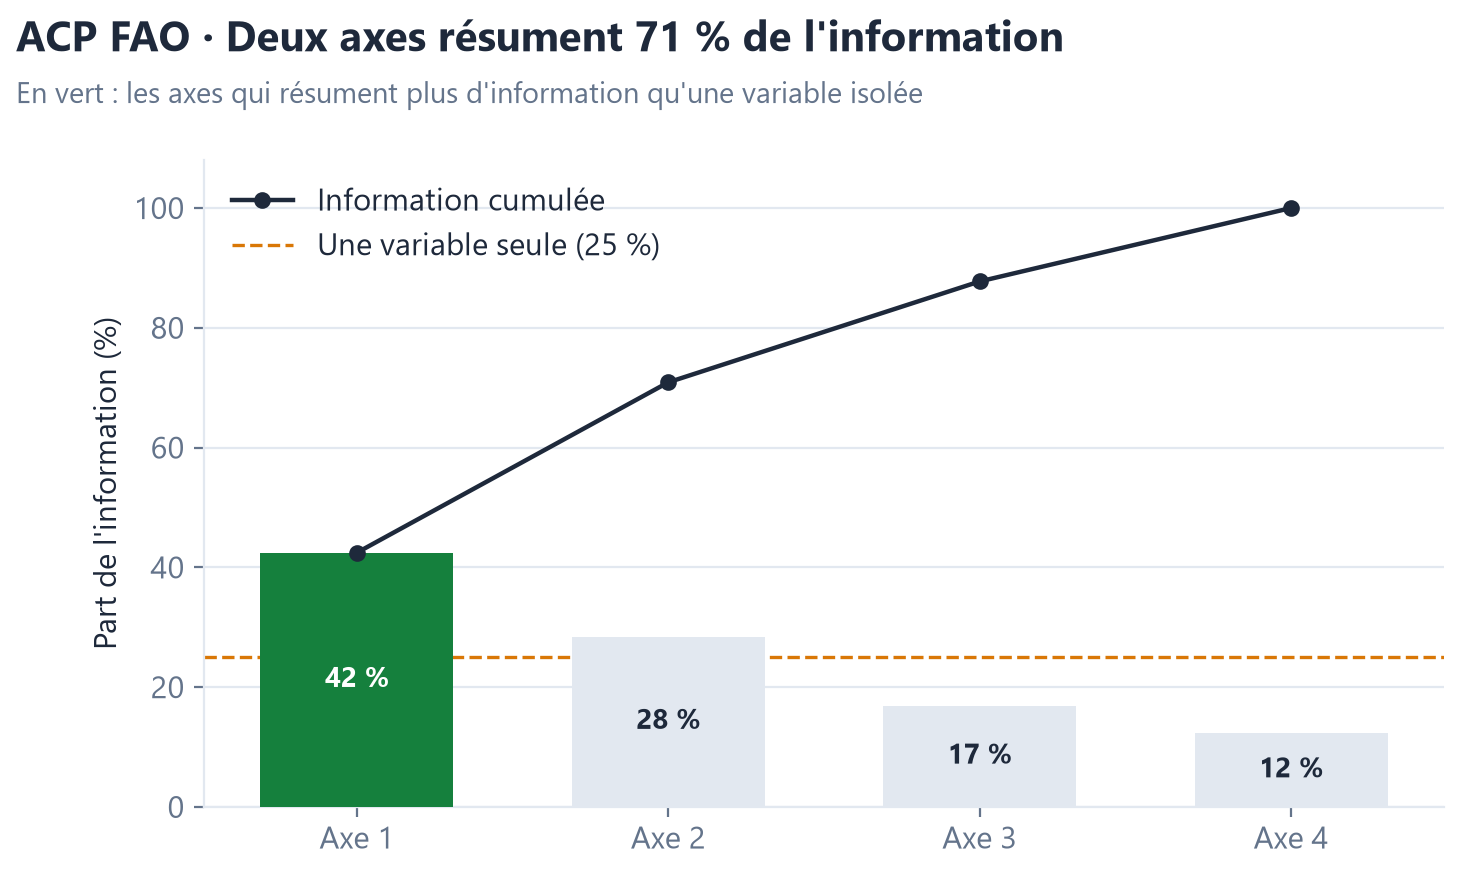

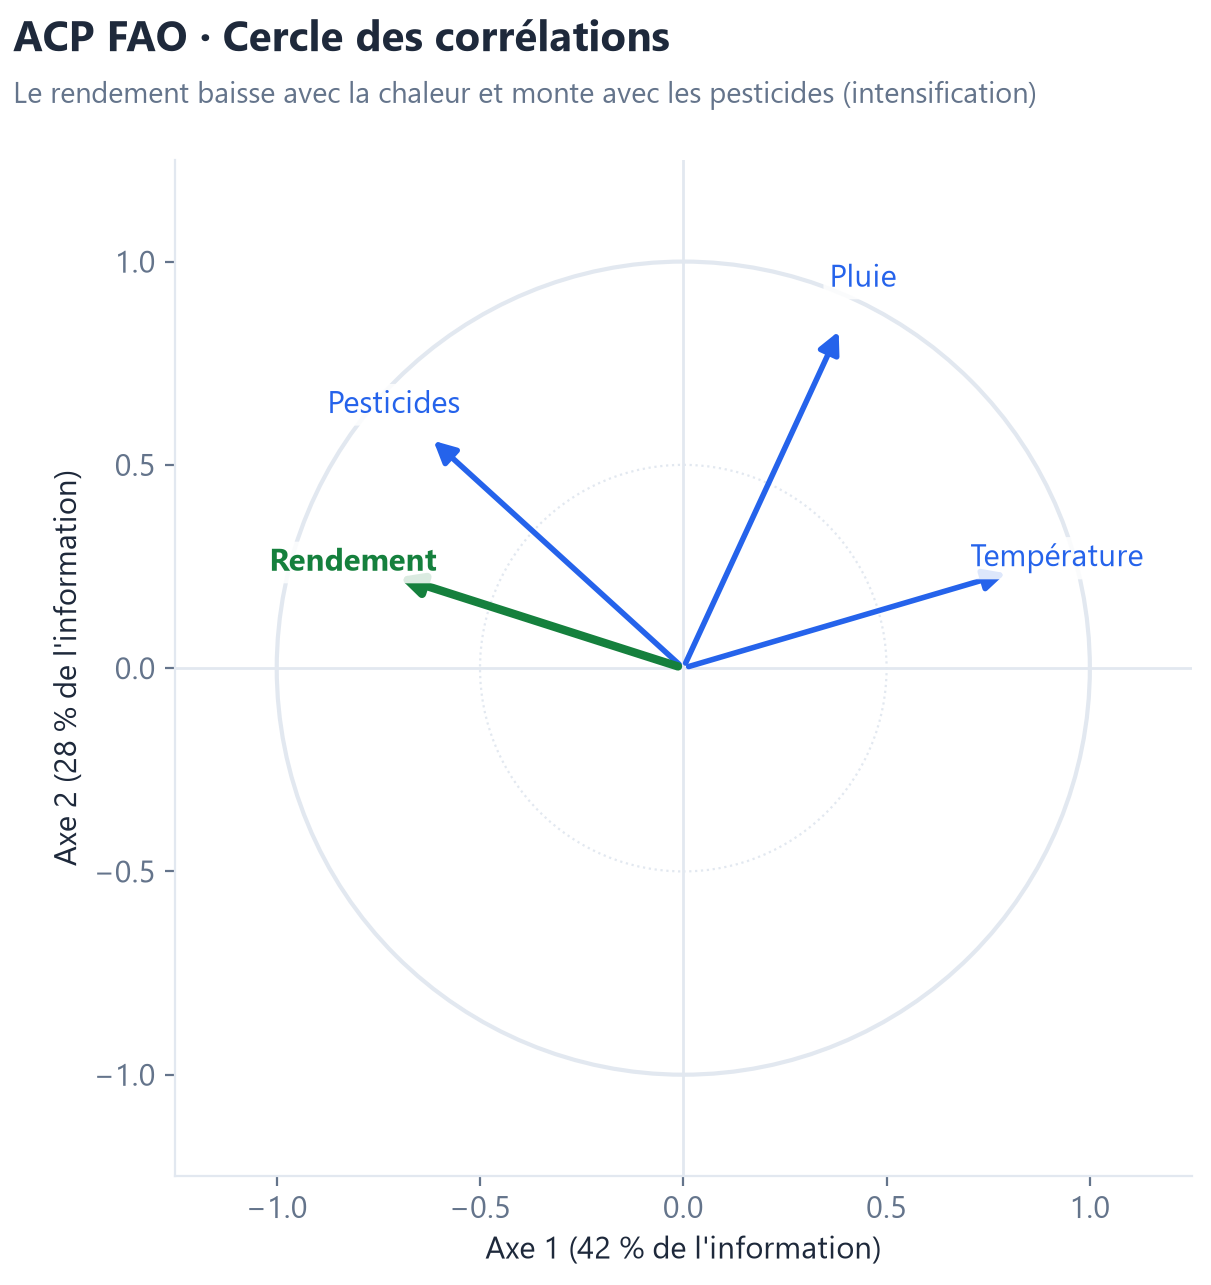

,F1,F2,F3
Pluie,0.388,0.841,0.039
Température,0.806,0.237,0.239
Pesticides,-0.624,0.568,-0.422
Rendement,-0.713,0.228,0.661


In [7]:
acp.fig_eboulis(res2, f"ACP FAO · Deux axes résument {res2.inertie_pct.iloc[:2].sum():.0f} % de l'information",
                acp.SORTIE / "05_fao_eboulis.png")
acp.fig_cercle(res2, "ACP FAO · Cercle des corrélations", acp.SORTIE / "06_fao_cercle.png",
               "Le rendement baisse avec la chaleur et monte avec les pesticides (intensification)")
display(Image(acp.SORTIE / "05_fao_eboulis.png", width=700))
display(Image(acp.SORTIE / "06_fao_cercle.png", width=560))
res2.correlations.iloc[:, :3].rename(index=acp.LIBELLES)

**Lecture.**
- **Axe 1 (42 %) : « climat chaud et agriculture extensive » contre « climat tempéré et agriculture intensive ».** La température (+0,81) s'y oppose au rendement (−0,71) et aux pesticides (−0,62). Dans les données réelles, **la chaleur fait baisser les rendements** et **l'intensification les fait monter**.
- **Axe 2 (28 %) : la pluie** (+0,84). Elle est presque sans lien avec le rendement (corrélation −0,08). Les pays secs irriguent, et une moyenne annuelle nationale ne dit pas grand-chose de l'eau reçue par une parcelle.
- **Axe 3 (17 %) : le rendement propre à chaque culture**, examiné ci-dessous.

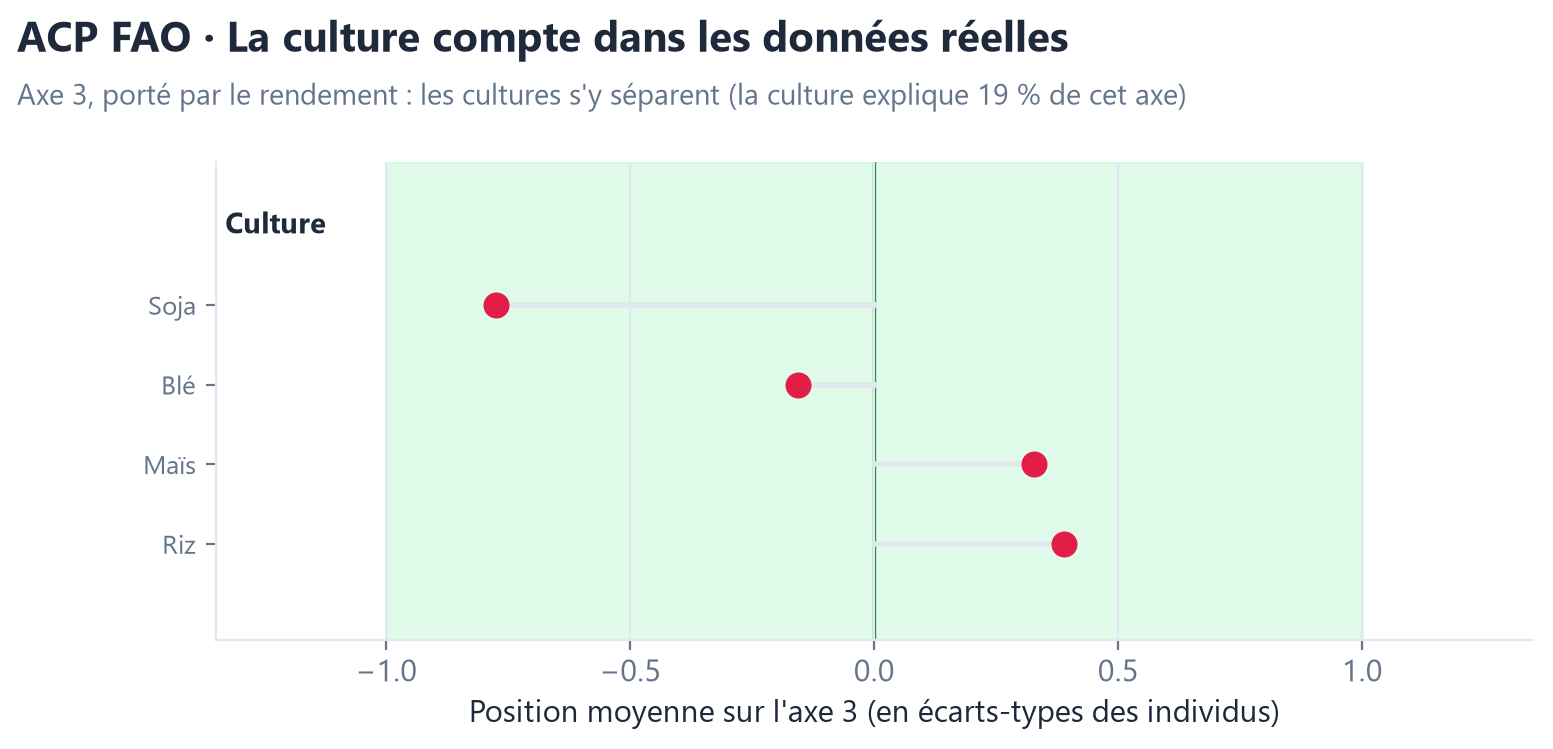

,Rendement médian FAO (t/ha)
Crop,
Maïs,2.449
Riz,3.355
Soja,1.620
Blé,2.432


In [8]:
axe = res2.eta2_pct.loc["Crop"].idxmax()
acp.fig_qualitatives(res2, "ACP FAO · La culture compte dans les données réelles", acp.SORTIE / "07_fao_cultures.png",
                     f"Axe {axe[1:]}, porté par le rendement : les cultures s'y séparent "
                     f"(la culture explique {res2.eta2_pct.loc['Crop', axe]:.0f} % de cet axe)", axe=axe)
display(Image(acp.SORTIE / "07_fao_cultures.png", width=680))
fao.groupby("Crop")["yield_t_ha"].median().rename(index=acp.MODALITES_FR).rename("Rendement médian FAO (t/ha)").to_frame()

**Lecture.** Contrairement à DS1, **la culture sépare nettement les rendements réels.**
- Le riz a les rendements les plus élevés (médiane 3,4 t/ha).
- Le soja a les plus bas (1,6 t/ha).
- Le maïs et le blé se situent entre les deux (environ 2,4 t/ha).

La culture est donc une variable clé, ce que DS1 ne pouvait pas montrer.

## 3. Synthèse : les variables clés retenues

On compare la force du lien avec le rendement dans chaque source, sur une échelle de 0 à 1 :
- pour une variable numérique, la valeur absolue de la corrélation ;
- pour une variable qualitative, le rapport de corrélation ;
- pour le modèle final de l'étape 2, l'importance des variables, ramenée à 1 pour la plus importante.

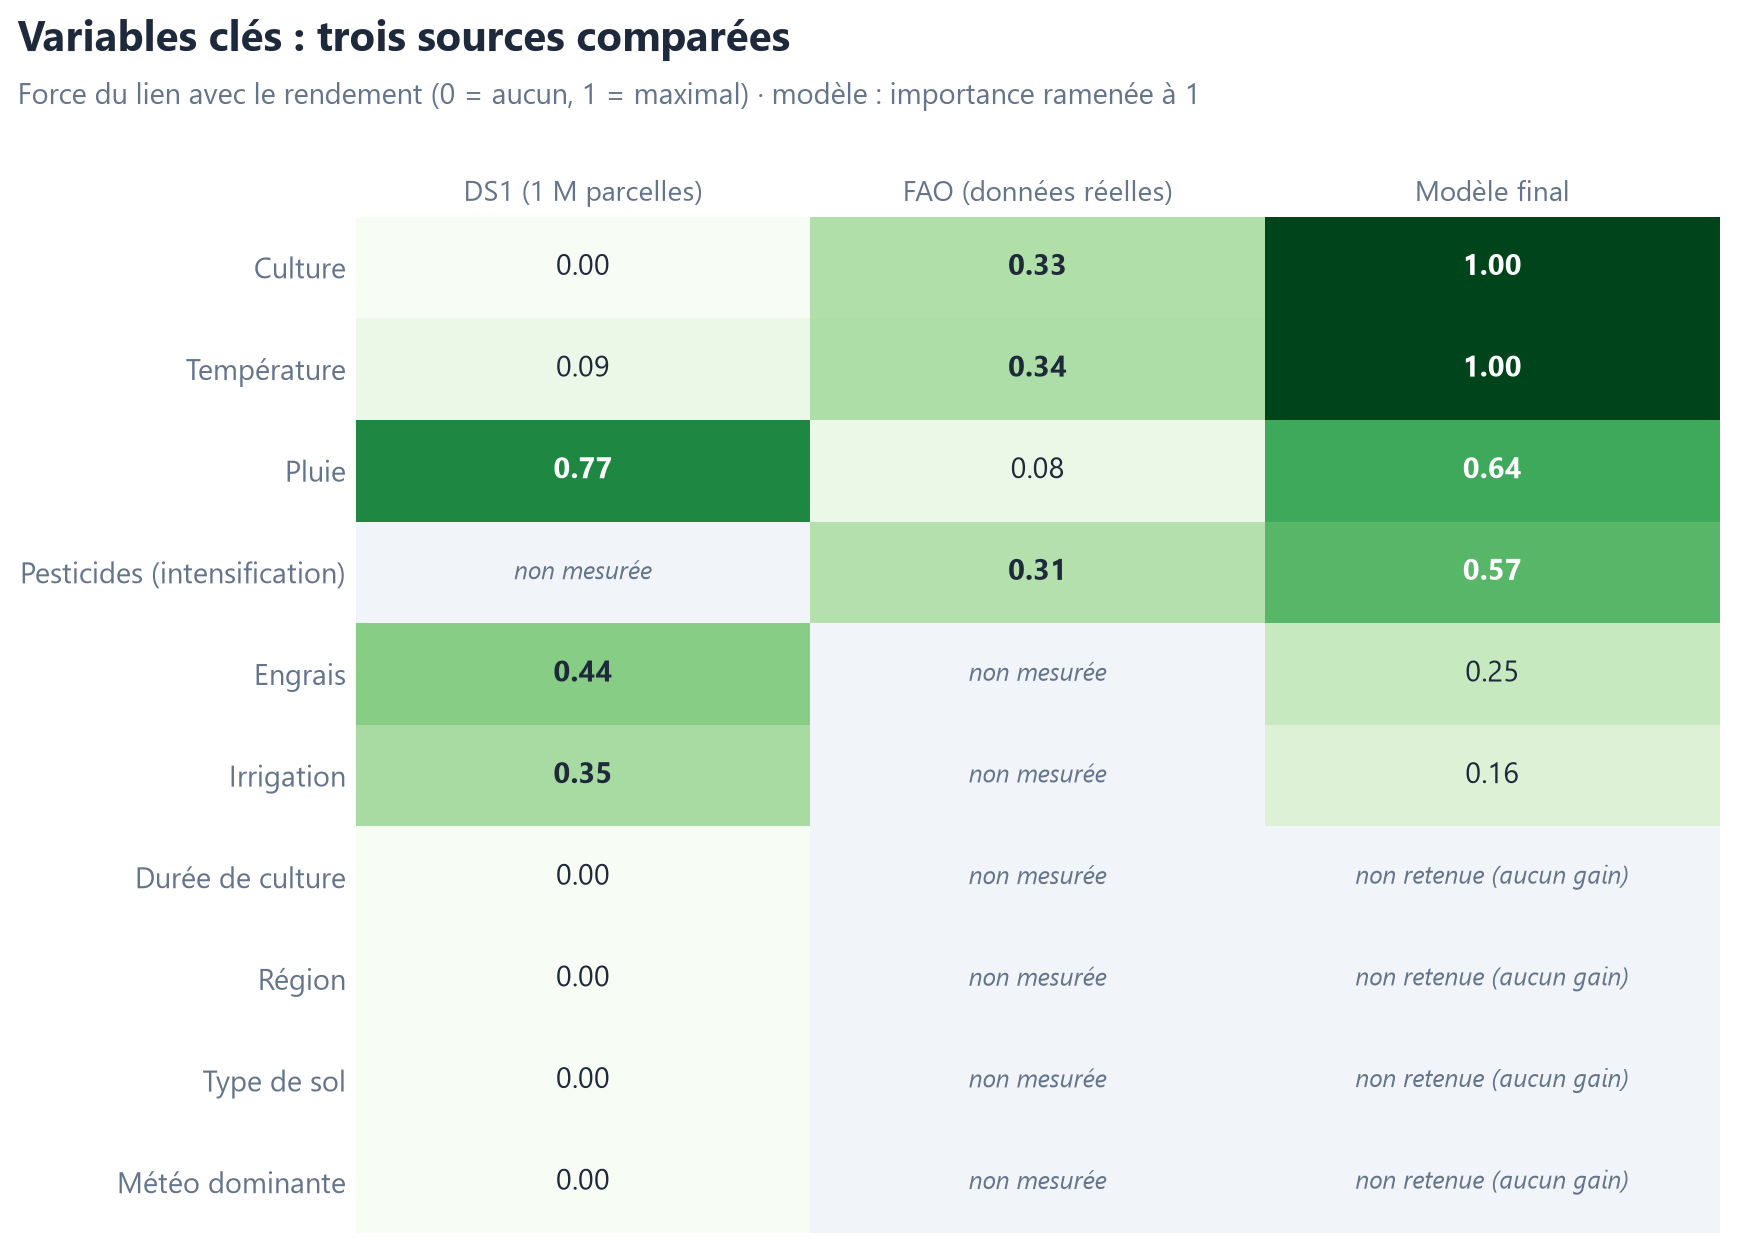

,DS1 (1 M parcelles),FAO (données réelles),Modèle final
Culture,0.002,0.325,0.997
Température,0.085,0.335,1.000
Pluie,0.765,0.080,0.636
Pesticides (intensification),NaN,0.314,0.569
Engrais,0.442,NaN,0.249
Irrigation,0.353,NaN,0.157
Durée de culture,0.003,NaN,NaN
Région,0.002,NaN,NaN
Type de sol,0.002,NaN,NaN
Météo dominante,0.001,NaN,NaN


In [9]:
synthese = acp.tableau_synthese(ds1, fao)
acp.fig_synthese(synthese, acp.SORTIE / "08_synthese_variables_cles.png")
display(Image(acp.SORTIE / "08_synthese_variables_cles.png", width=760))
synthese

| Variable | Verdict | Justification |
|---|---|---|
| **Culture** | Clé | Sans effet dans DS1 (synthétique), mais elle sépare nettement les rendements réels (FAO). C'est la 2ᵉ variable du modèle |
| **Température** | Clé | Faible dans DS1, mais la chaleur fait nettement baisser les rendements réels. C'est la 1ʳᵉ variable du modèle |
| **Pluie** | Clé | 1ʳᵉ variable de DS1, presque neutre dans la FAO (l'irrigation compense). Elle garde un rôle important dans le modèle |
| **Pesticides** | Clé (indicateur d'intensification) | Liés aux rendements réels élevés. 4ᵉ variable du modèle |
| **Engrais** | Clé | 2ᵉ variable de DS1 (+50 % de rendement environ). Absent de la FAO |
| **Irrigation** | Clé | 3ᵉ variable de DS1 (+40 % environ). Absente de la FAO |
| Durée de culture | Non retenue | Aucun lien avec le rendement dans DS1 |
| Région, type de sol, météo dominante | Non retenues pour l'instant | Aucun lien mesurable dans DS1, où elles ont été générées au hasard. Le modèle sans elles est aussi précis (étape 2). À réintroduire avec des données réelles, en priorité le sol |

**Conclusion.** L'ACP, recoupée par les mesures de lien et par le modèle, réduit les 10 variables de départ à **6 variables clés** : culture, température, pluie, pesticides, engrais et irrigation. Ce sont exactement les 6 variables du modèle final et de l'application. Ce verdict vaut **pour les données disponibles** : avec des mesures de sol réelles, l'analyse serait à refaire.

**Ce que la validation apporte.** Les données réelles corrigent la vision donnée par DS1 seul. Le climat (la chaleur) et le choix de la culture comptent davantage que la pluie, que DS1 surestime.

In [10]:
# Tableaux chiffrés repris dans le rapport métier
for nom, res in (("ds1", res1), ("fao", res2)):
    pd.DataFrame({"valeur_propre": res.valeurs_propres, "inertie_pct": res.inertie_pct,
                  "inertie_cumulee_pct": res.inertie_pct.cumsum()}).round(3).to_csv(acp.SORTIE / f"{nom}_valeurs_propres.csv")
    res.correlations.round(3).to_csv(acp.SORTIE / f"{nom}_correlations.csv")
    res.eta2_pct.round(4).to_csv(acp.SORTIE / f"{nom}_eta2_qualitatives.csv")
synthese.to_csv(acp.SORTIE / "synthese_variables_cles.csv")
print("Tableaux enregistrés dans", acp.SORTIE)

Tableaux enregistrés dans C:\Users\j-a-b\Documents\OpenClassrooms\Projet 11 système de recommandations pour une agriculture optimisée par les données\reports\acp
